# Electron–electron and electron–ion covariance

**Question.** Does the electron–ion covariance have any shape beyond the footprint of one shared shot-to-shot
fluctuation?

If both spectra depend on the shot only through a single fluctuating parameter $I$ (pulse energy in the
interaction region, gas density, pointing, detector gain …) plus independent counting noise, then
$\mathrm{Cov}(D_i, C_j) \approx \mathrm{Var}(I)\;\partial_I\langle D_i\rangle\;\partial_I\langle C_j\rangle$:
the outer product of one electron vector and one ion vector (**rank 1**). Anything that needs more than one such
term is structure: an electron feature that goes with one ion peak but not another, coincident emission, detector
crosstalk.

**Data.** Run 60538, argon (`Argon_2807259185`), 100 pulses/train. Aggregates from `compute_aggregates.py`
(per GMD bin: ⟨D⟩, ⟨C⟩, ⟨DDᵀ⟩, ⟨CCᵀ⟩, ⟨DCᵀ⟩, ⟨DG⟩, ⟨CG⟩, ⟨G⟩, ⟨G²⟩ with D = electron TOF histogram,
C = ion TOF histogram, G = GMD, all per shot). Electron TOF = TDC channel 2, ion TOF = channel 1
(`config.TDC_CHANNEL_E/I`):

```
python write_h5.py Argon_2807259185 1 60538 --max-ecounts 120 --max-icounts 50 \
       -o 11024642/processed/combined/run60538_Argon_2807259185.h5
python analysis/scripts/compute_aggregates.py analysis/configs/aggregates_run60538_argon.py \
       11024642/processed/combined/run60538_Argon_2807259185.h5          # all 100 pulses
python analysis/scripts/compute_aggregates.py analysis/configs/aggregates_run60538_argon_b0-20.py \
       11024642/processed/combined/run60538_Argon_2807259185.h5          # first 20 pulses
```

The electron TOF is binned 50–1000 ns and the ion TOF 200–3400 ns. Fast electrons from the ion spectrometer reach the
electron TOF ~25 ns after each ion hit. That crosstalk arrives after the electron spectrum, so the electron window
stops at 1000 ns. Section 3b checks for any that is left.

**Steps.**
1. Pool the chosen GMD bins and merge TOF bins (exact on aggregates: covariances of merged bins add).
2. Three covariance estimates, each removing more of the intensity-driven part:
   **total** (all shots as one sample) → **within GMD bins** (mean covariance inside each GMD bin; whatever follows the
   measured pulse energy from bin to bin is gone, linear or not) → **partial on GMD** (also the linear GMD
   dependence inside each bin).
3. e–e and e–i covariance maps, with significance in standard errors.
4. Electron spectra covarying with different ion TOF windows, and vice versa. Under rank 1 they all have one shape.
5. Rank test: canonical correlations between D and C against the noise edge. Components beyond the first are structure.
6. The e–i covariance left after removing the leading component.
7. The same per GMD bin.

TOF in ns (the H5 files store TDC units of 100 ps; converted on loading), GMD in µJ, counts per shot.

In [1]:
# ---- Imports and paths ------------------------------------------------------
from pathlib import Path
import sys
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

# Repo root = the first folder above the working directory that holds analysis/scripts/config.py
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "analysis" / "scripts" / "config.py").exists())
sys.path.insert(0, str(REPO_ROOT / "analysis" / "scripts"))
import config
from compute_aggregates import load_aggregates

for msg in ("invalid value encountered", "divide by zero"):
    warnings.filterwarnings("ignore", message=msg)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
# ---- Parameters ---------------------------------------------------------------
AGG_H5 = "run60538_Argon_2807259185_aggregates.h5"   # relative to config.COMBINED_DIR, or absolute
                                                      # ("..._aggregates_b0-20.h5": first 20 pulses only)
GMD_BINS = None          # indices of the aggregate GMD bins to use, e.g. [4, 5, 6]; None = all non-empty
REBIN_E = 1              # merge N aggregate TOF bins (5 ns each): 1 -> 5 ns
REBIN_I = 4              # 4 -> 20 ns
E_RANGE = None           # (lo, hi) electron TOF kept, ns; None = whole aggregate range (50-1000 ns)
I_RANGE = None           # (lo, hi) ion TOF kept, ns; None = whole aggregate range (200-3400 ns)
MIN_MEAN = 1e-3          # TOF bins with fewer counts per shot stay out of the rank test (sections 5-7)

DIAG_MASK = 1            # e–e maps: blank |i − j| <= DIAG_MASK (Poisson variance sits on the diagonal)
CLIP_PCT = 99.5          # covariance colour scale: ± this percentile of |value|
Z_MAX = 6                # significance colour scale: ± Z_MAX standard errors

# TOF windows (ns) for the covariance-filtered spectra of section 4
E_WINDOWS = [(85, 100), (100, 110), (110, 200), (230, 265), (320, 470), (470, 950)]
ION_WINDOWS = [(240, 520), (1000, 1420), (1440, 1520), (1640, 1780), (1960, 2240), (2400, 2600), (2660, 2760),
               (2840, 3120)]
WINDOW_EST = "partial on GMD"    # estimate used in sections 4 and 5b: "total", "within GMD bins", "partial on GMD"
N_COMPONENTS = 4                 # canonical components plotted in section 5b

## 1. Load and pool

In [3]:
# ---- Load the aggregates --------------------------------------------------------
agg_path = Path(AGG_H5)
agg_path = agg_path if agg_path.is_absolute() else config.COMBINED_DIR / agg_path
agg = load_aggregates(agg_path)
meta = agg.metadata
TDC_NS = 0.1                                     # ns per TDC unit
e_edges0 = TDC_NS * agg.tof_edges                # aggregate TOF bin edges in ns
i_edges0 = TDC_NS * agg.ion_tof_edges
print(agg_path)
for k in ("input_h5", "bunch_range", "trim_start", "trim_end", "max_hits_e", "max_hits_i",
          "n_skipped_gmd_oor", "n_skipped_gmd_nan", "n_skipped_max_hits"):
    print(f"  {k:20s} {meta.get(k)}")
print(f"  electron TOF {agg.n_tof} bins {e_edges0[0]:.0f}..{e_edges0[-1]:.0f} ns, "
      f"ion TOF {agg.n_tof_i} bins {i_edges0[0]:.0f}..{i_edges0[-1]:.0f} ns")
print("\n bin  GMD range (uJ)     shots    <G>   e/shot  i/shot")
for b in range(agg.n_gmd_bins):
    print(f" {b:3d}  {agg.gmd_edges[b]:5.3f}-{agg.gmd_edges[b + 1]:5.3f}  {agg.n_per_bin[b]:8d}  {agg.G[b]:6.3f}"
          f"  {np.nansum(agg.D[b]):6.3f}  {np.nansum(agg.C[b]):6.3f}")

/home/ogalex/gas-vls/11024642/processed/combined/run60538_Argon_2807259185_aggregates.h5
  input_h5             11024642/processed/combined/run60538_Argon_2807259185.h5
  bunch_range          [0, 100]
  trim_start           3
  trim_end             3
  max_hits_e           60
  max_hits_i           30
  n_skipped_gmd_oor    25504
  n_skipped_gmd_nan    0
  n_skipped_max_hits   9
  electron TOF 190 bins 50..1000 ns, ion TOF 640 bins 200..3400 ns

 bin  GMD range (uJ)     shots    <G>   e/shot  i/shot
   0  0.020-0.040     44229   0.031   1.365   0.397
   1  0.040-0.060     52930   0.050   1.637   0.512
   2  0.060-0.085     58194   0.072   2.048   0.678
   3  0.085-0.115     59882   0.100   2.513   0.878
   4  0.115-0.150     62482   0.132   2.973   1.073
   5  0.150-0.190     64157   0.169   3.504   1.293
   6  0.190-0.240     61205   0.214   4.121   1.555
   7  0.240-0.310     59378   0.272   4.893   1.863
   8  0.310-0.430     58061   0.364   5.957   2.300
   9  0.430-0.650     42018

In [4]:
# ---- Select GMD bins, merge TOF bins --------------------------------------------
def rebin_matrix(edges, factor, rng):
    # (n_old, n_new) 0/1 matrix summing `factor` neighbouring bins inside rng, and the new edges
    inside = np.ones(len(edges) - 1, bool) if rng is None else (edges[:-1] >= rng[0]) & (edges[1:] <= rng[1])
    idx = np.where(inside)[0]
    idx = idx[: len(idx) // factor * factor]
    R = np.zeros((len(edges) - 1, len(idx) // factor))
    R[idx, np.arange(len(idx)) // factor] = 1
    return R, np.append(edges[idx[::factor]], edges[idx[-1] + 1])


Re, e_edges = rebin_matrix(e_edges0, REBIN_E, E_RANGE)     # edges in ns
Ri, i_edges = rebin_matrix(i_edges0, REBIN_I, I_RANGE)
e_cent, i_cent = 0.5 * (e_edges[1:] + e_edges[:-1]), 0.5 * (i_edges[1:] + i_edges[:-1])

bins = np.arange(agg.n_gmd_bins) if GMD_BINS is None else np.asarray(GMD_BINS)
bins = bins[agg.n_per_bin[bins] > 0]
n_b = agg.n_per_bin[bins].astype(float)          # shots per GMD bin
N = n_b.sum()

# Per-bin means in the merged basis; first axis = GMD bin
D, C = agg.D[bins] @ Re, agg.C[bins] @ Ri          # <D>, <C>         (nb, ne), (nb, ni)
G, GG = agg.G[bins], agg.GtG[bins]                 # <G>, <G²>        (nb,)
DD = Re.T @ agg.DtD[bins] @ Re                     # <D Dᵀ>           (nb, ne, ne)
CC = Ri.T @ agg.CtC[bins] @ Ri                     # <C Cᵀ>           (nb, ni, ni)
DC = Re.T @ agg.DtC[bins] @ Ri                     # <D Cᵀ>           (nb, ne, ni)
DG, CG = agg.DtG[bins] @ Re, agg.CtG[bins] @ Ri     # <D G>, <C G>     (nb, ne), (nb, ni)
print(f"{len(bins)} GMD bins, {N:.0f} shots; {len(e_cent)} electron x {len(i_cent)} ion TOF bins")

11 GMD bins, 579587 shots; 190 electron x 160 ion TOF bins


## 2. Three covariance estimates
`EST[name]` holds `DD`, `CC`, `DC` (covariance matrices) and `se_DD`, `se_DC` (standard error of each entry,
$\sqrt{\mathrm{Var}(D_i)\mathrm{Var}(C_j)/N}$, the Gaussian-limit error when there is no true covariance).
The per-GMD-bin pieces `cDD, cCC, cDC` (covariance) and `pDD, pCC, pDC` (partial on GMD) stay available.

In [5]:
# ---- Covariances ------------------------------------------------------------------
outer = lambda a, b: a[..., :, None] * b[..., None, :]    # (batched) outer product
w = n_b / N                                               # shot fraction per GMD bin
wmean = lambda x: np.tensordot(w, x, axes=1)              # shot-weighted mean over GMD bins

# inside each GMD bin
cDD, cCC, cDC = DD - outer(D, D), CC - outer(C, C), DC - outer(D, C)
cDG, cCG, vG = DG - D * G[:, None], CG - C * G[:, None], GG - G ** 2
# ... with the linear GMD dependence removed (partial covariance on G)
pDD = cDD - outer(cDG, cDG) / vG[:, None, None]
pCC = cCC - outer(cCG, cCG) / vG[:, None, None]
pDC = cDC - outer(cDG, cCG) / vG[:, None, None]

mD, mC = wmean(D), wmean(C)                               # mean spectra, counts per shot
EST = {
    # all selected shots as one sample: includes everything the pulse energy drives
    "total": {"DD": wmean(DD) - np.outer(mD, mD), "CC": wmean(CC) - np.outer(mC, mC),
              "DC": wmean(DC) - np.outer(mD, mC)},
    # mean covariance inside the GMD bins: what follows the GMD from bin to bin is gone
    "within GMD bins": {"DD": wmean(cDD), "CC": wmean(cCC), "DC": wmean(cDC)},
    # ... and the linear GMD dependence inside each bin too
    "partial on GMD": {"DD": wmean(pDD), "CC": wmean(pCC), "DC": wmean(pDC)},
}
for E in EST.values():
    vd, vc = np.clip(np.diag(E["DD"]), 0, None), np.clip(np.diag(E["CC"]), 0, None)
    E["se_DD"] = np.sqrt(np.outer(vd, vd) / N)
    E["se_DC"] = np.sqrt(np.outer(vd, vc) / N)
    for k in ("se_DD", "se_DC"):
        E[k][E[k] == 0] = np.nan                         # empty bins: no significance


def show_map(ax, M, x_edges, y_edges, vmax=None, label=None, cmap="RdBu_r"):
    # pcolormesh, symmetric colour scale (± CLIP_PCT percentile of |M| unless vmax is given)
    if vmax is None:
        vmax = np.nanpercentile(np.abs(M), CLIP_PCT) or 1.0
    mesh = ax.pcolormesh(x_edges, y_edges, M, cmap=cmap, vmin=-vmax, vmax=vmax, shading="flat")
    plt.colorbar(mesh, ax=ax, label=label, fraction=0.046, pad=0.02)
    return mesh

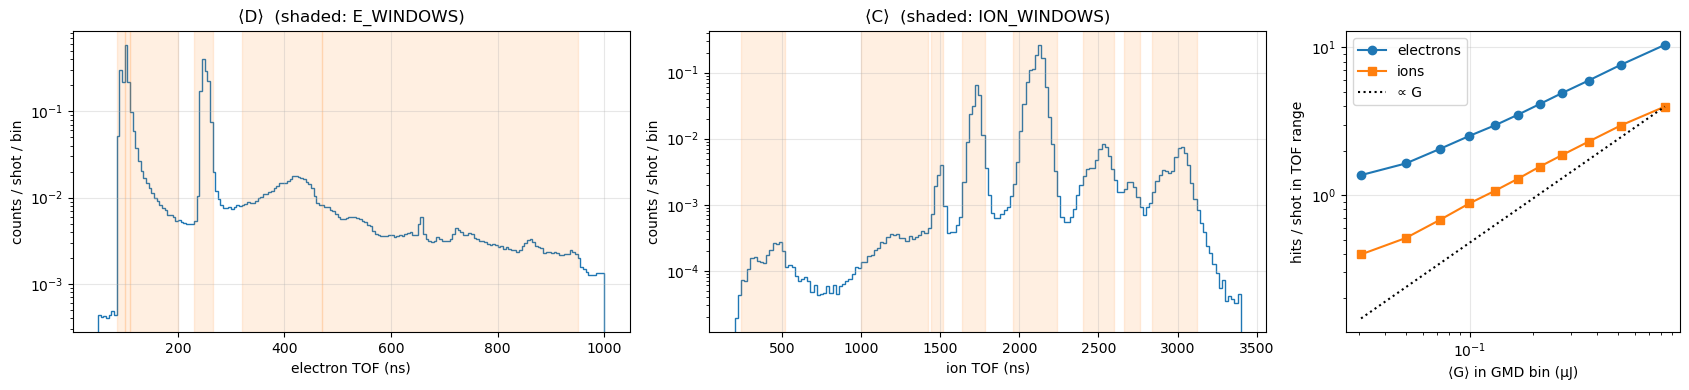

In [6]:
# ---- Mean spectra and yields per GMD bin -------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(17, 4), gridspec_kw={"width_ratios": [2, 2, 1.2]})
ax[0].stairs(mD, e_edges)
ax[0].set(xlabel="electron TOF (ns)", ylabel="counts / shot / bin", title="⟨D⟩  (shaded: E_WINDOWS)", yscale="log")
ax[1].stairs(mC, i_edges)
ax[1].set(xlabel="ion TOF (ns)", ylabel="counts / shot / bin", title="⟨C⟩  (shaded: ION_WINDOWS)", yscale="log")
for lo, hi in E_WINDOWS:
    ax[0].axvspan(lo, hi, color="C1", alpha=0.12)
for lo, hi in ION_WINDOWS:
    ax[1].axvspan(lo, hi, color="C1", alpha=0.12)
ax[2].loglog(G, D.sum(1), "o-", label="electrons")
ax[2].loglog(G, C.sum(1), "s-", label="ions")
ax[2].loglog(G, G / G[-1] * C.sum(1)[-1], "k:", label="∝ G")
ax[2].set(xlabel="⟨G⟩ in GMD bin (µJ)", ylabel="hits / shot in TOF range")
ax[2].legend()
fig.tight_layout()
plt.show()

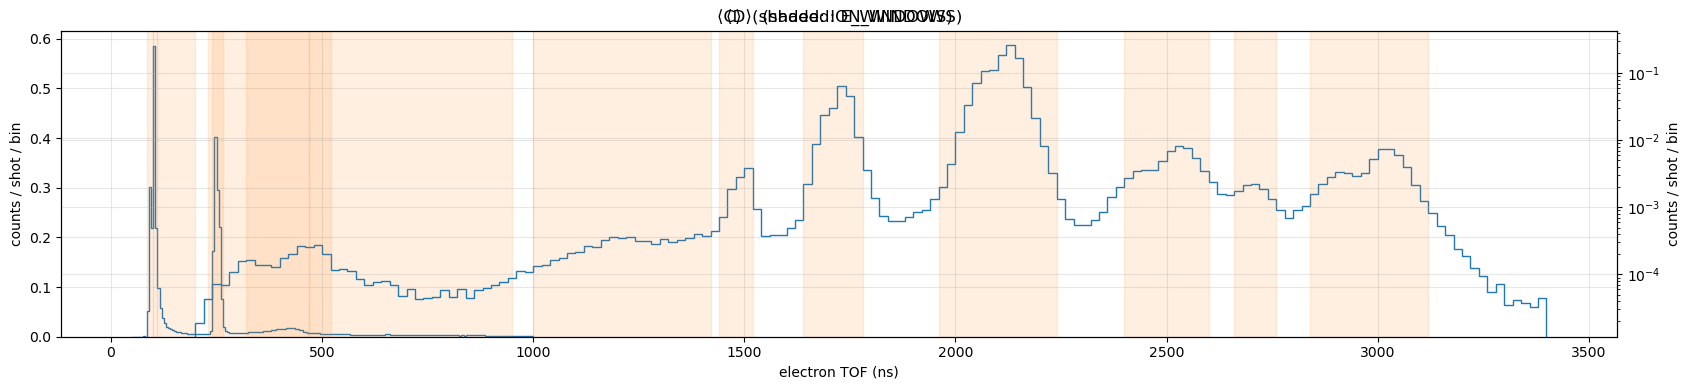

In [7]:
# ---- Mean spectra and yields per GMD bin -------------------------------------------
fig, ax = plt.subplots(figsize=(17, 4))
ax.stairs(mD, e_edges)
ax.set(xlabel="electron TOF (ns)", ylabel="counts / shot / bin", title="⟨D⟩  (shaded: E_WINDOWS)")
ax1 = ax.twinx()
ax1.stairs(mC, i_edges)
ax1.set(xlabel="ion TOF (ns)", ylabel="counts / shot / bin", title="⟨C⟩  (shaded: ION_WINDOWS)", yscale="log")
for lo, hi in E_WINDOWS:
    ax.axvspan(lo, hi, color="C1", alpha=0.12)
for lo, hi in ION_WINDOWS:
    ax1.axvspan(lo, hi, color="C1", alpha=0.12)
fig.tight_layout()
plt.show()

## 3. Covariance maps
Top row: covariance; bottom row: the same in standard errors. Left to right the intensity-driven part is removed
step by step. For e–e the diagonal band (`DIAG_MASK`) is blanked: it holds the Poisson variance, and detector dead
time shows up just next to it as negative covariance.

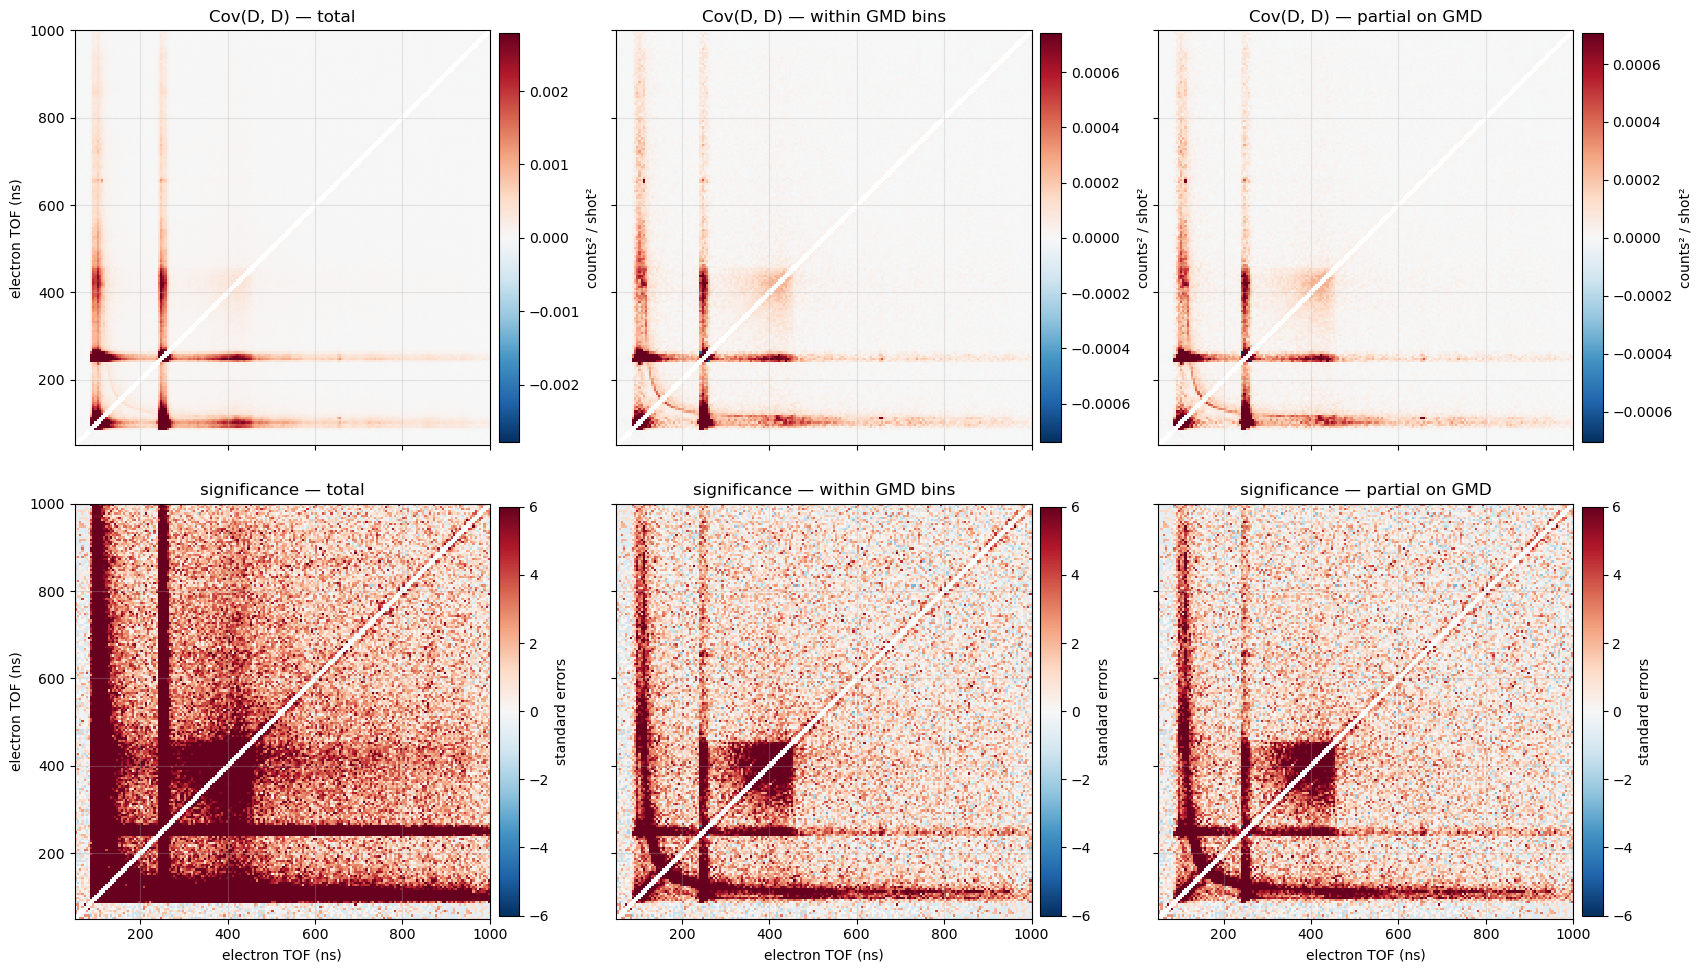

In [8]:
# ---- e–e covariance -----------------------------------------------------------------
band = np.abs(np.subtract.outer(np.arange(len(e_cent)), np.arange(len(e_cent)))) <= DIAG_MASK
fig, ax = plt.subplots(2, 3, figsize=(17, 10), sharex=True, sharey=True)
for k, (name, E) in enumerate(EST.items()):
    M = np.where(band, np.nan, E["DD"])
    show_map(ax[0, k], M, e_edges, e_edges, label="counts² / shot²")
    show_map(ax[1, k], M / E["se_DD"], e_edges, e_edges, vmax=Z_MAX, label="standard errors")
    ax[0, k].set_title(f"Cov(D, D) — {name}")
    ax[1, k].set_title(f"significance — {name}")
    ax[1, k].set_xlabel("electron TOF (ns)")
for a in ax[:, 0]:
    a.set_ylabel("electron TOF (ns)")
for a in ax.flat:
    a.set_aspect("equal")
fig.tight_layout()
plt.show()

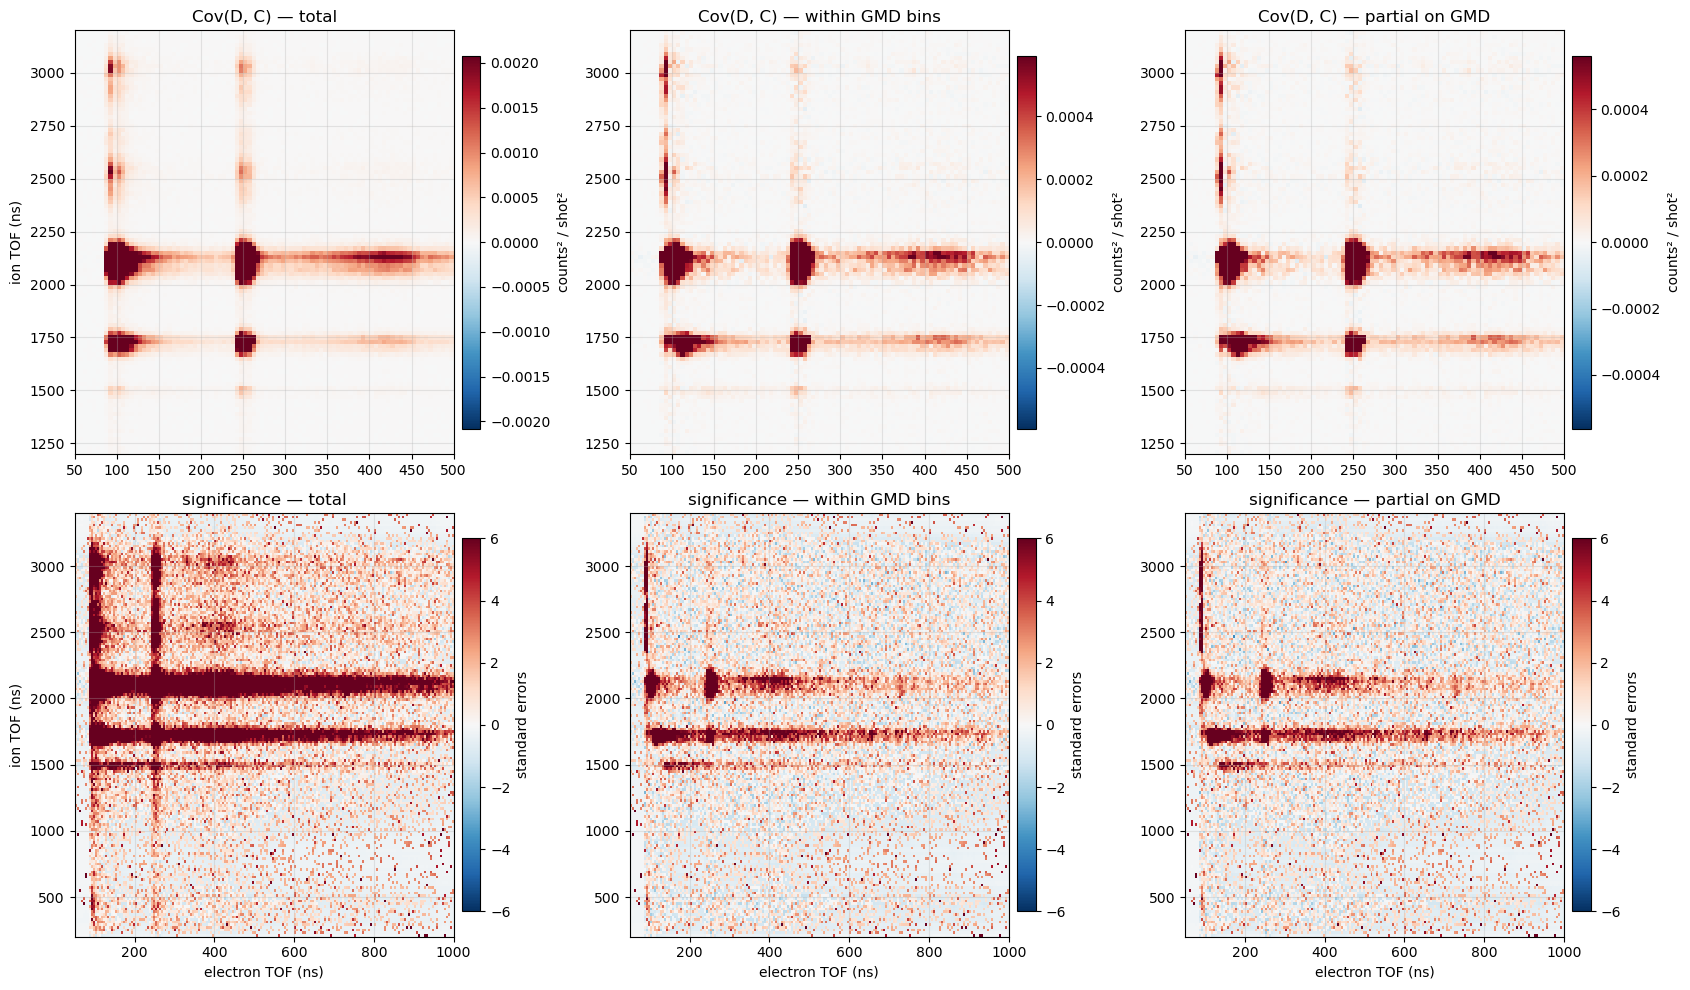

In [32]:
# ---- e–i covariance -----------------------------------------------------------------
fig, ax = plt.subplots(2, 3, figsize=(17, 10), sharex=False, sharey=False)
for k, (name, E) in enumerate(EST.items()):
    show_map(ax[0, k], E["DC"].T, e_edges, i_edges, label="counts² / shot²")
    show_map(ax[1, k], (E["DC"] / E["se_DC"]).T, e_edges, i_edges, vmax=Z_MAX, label="standard errors")
    ax[0, k].set_title(f"Cov(D, C) — {name}")
    ax[1, k].set_title(f"significance — {name}")
    ax[1, k].set_xlabel("electron TOF (ns)")
    ax[0, k].set_ylim(1200, 3200)
    ax[0, k].set_xlim(50, 500)
for a in ax[:, 0]:
    a.set_ylabel("ion TOF (ns)")
fig.tight_layout()
plt.show()

In [10]:
((np.array([1495, 1730, 2120, 2520, 2690, 3020])/2120)**2)*20

array([ 9.94582147, 13.31835173, 20.        , 28.25916696, 32.2005162 ,
       40.58561766])

### 3b. Crosstalk check: e–i covariance against t_electron − t_ion
Each ion hit can put a hit on the electron channel ~25 ns later (fast electrons from the ion spectrometer). In the
e–i covariance that is a line at fixed $t_\mathrm{electron} - t_\mathrm{ion}$. The main ion peaks (>1400 ns) arrive
after the 1000 ns electron window, so only the light ions at 250–500 ns can still put crosstalk inside it. Summing
the covariance along lines of constant $t_\mathrm{electron} - t_\mathrm{ion}$, at the aggregates' own 5 ns
resolution, turns any fixed-delay coupling into a narrow peak. Physics covariance spreads over many delays instead.
Partial on GMD, all selected GMD bins.

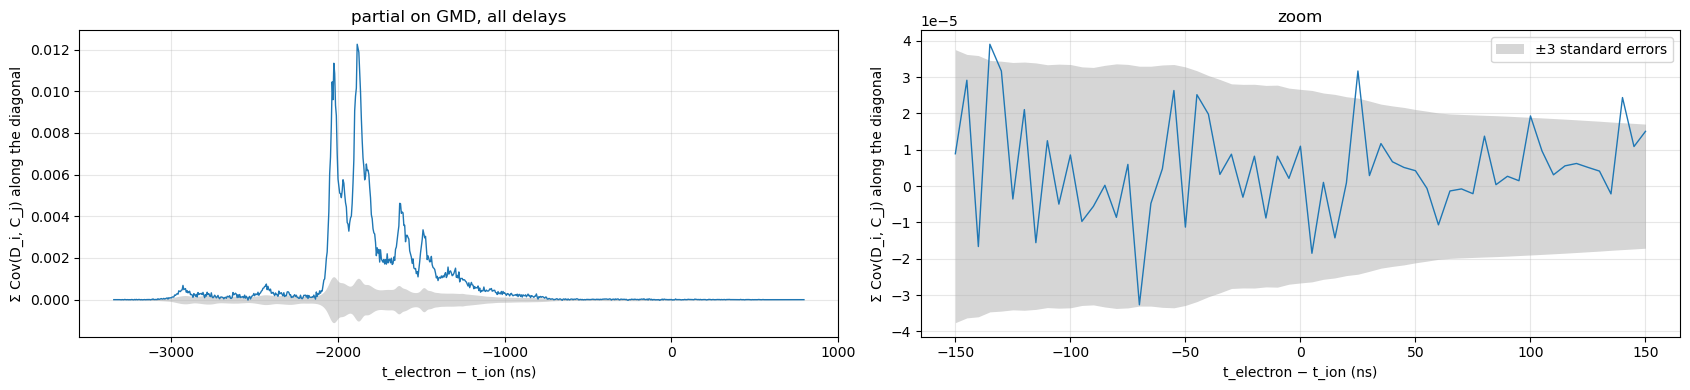

largest diagonal sum with 0 <= t_electron − t_ion <= 100 ns at 25 ns: 3.170e-05 (3.9 standard errors)


In [11]:
# ---- e–i covariance summed along diagonals (native TOF bins) -------------------------
bw_e, bw_i = np.diff(e_edges0), np.diff(i_edges0)
assert np.allclose(bw_e, bw_e[0]) and np.allclose(bw_i, bw_e[0]), "needs equal, uniform e and ion TOF bins"
bw = bw_e[0]
D0, C0 = agg.D[bins], agg.C[bins]
cDG0, cCG0 = agg.DtG[bins] - D0 * G[:, None], agg.CtG[bins] - C0 * G[:, None]
pDC0 = wmean(agg.DtC[bins] - outer(D0, C0) - outer(cDG0, cCG0) / vG[:, None, None])   # (n_tof, n_tof_i)
pvD0 = wmean(np.diagonal(agg.DtD[bins], axis1=1, axis2=2) - D0 ** 2 - cDG0 ** 2 / vG[:, None])
pvC0 = wmean(np.diagonal(agg.CtC[bins], axis1=1, axis2=2) - C0 ** 2 - cCG0 ** 2 / vG[:, None])

k = np.arange(-pDC0.shape[0] + 1, pDC0.shape[1])                 # diagonal offset = column − row index
dt = e_edges0[0] - i_edges0[0] - k * bw                          # t_electron − t_ion of that diagonal (ns)
var_prod = np.outer(pvD0, pvC0)
diag_sum = np.array([np.trace(pDC0, offset=o) for o in k])
diag_se = np.sqrt(np.array([np.trace(var_prod, offset=o) for o in k]) / N)

fig, ax = plt.subplots(1, 2, figsize=(17, 4))
for a, (lo, hi) in zip(ax, ((-np.inf, np.inf), (-150, 150))):
    m = (dt >= lo) & (dt <= hi)
    a.plot(dt[m], diag_sum[m], lw=1)
    a.fill_between(dt[m], -3 * diag_se[m], 3 * diag_se[m], color="0.6", alpha=0.4, lw=0, label="±3 standard errors")
    a.set(xlabel="t_electron − t_ion (ns)", ylabel="Σ Cov(D_i, C_j) along the diagonal")
ax[0].set_title("partial on GMD, all delays")
ax[1].set_title("zoom")
ax[1].legend()
fig.tight_layout()
plt.show()
m = (dt >= 0) & (dt <= 100)
j = np.flatnonzero(m)[np.argmax((diag_sum / diag_se)[m])]
print(f"largest diagonal sum with 0 <= t_electron − t_ion <= 100 ns at {dt[j]:.0f} ns: {diag_sum[j]:.3e} "
      f"({diag_sum[j] / diag_se[j]:.1f} standard errors)")

## 4. Covariance-filtered spectra
Left: the electron spectrum that covaries with the ions in each `ION_WINDOWS` entry, Cov(D, ΣC_window), divided by
its own sum (Σ in the legend) so the shapes can be compared. Right: the ion spectrum covarying with each electron
window. Under rank 1 all curves on a panel coincide within their bands (±1 standard error); the dashed line uses
every ion (electron) bin.

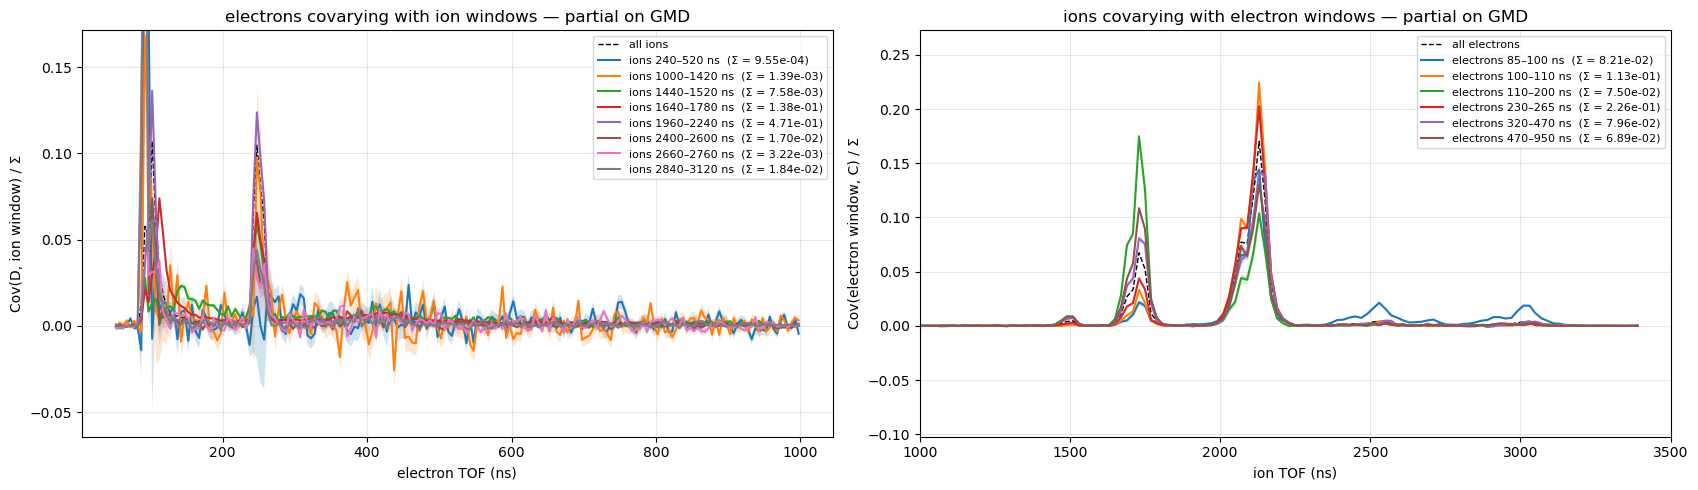

In [18]:
# ---- Electron spectra covarying with each ion window, and vice versa --------------
E = EST[WINDOW_EST]
in_win = lambda cent, lo, hi: ((cent >= lo) & (cent < hi)).astype(float)
var_D, var_C = np.clip(np.diag(E["DD"]), 0, None), np.clip(np.diag(E["CC"]), 0, None)

fig, ax = plt.subplots(1, 2, figsize=(17, 5))
ref = E["DC"].sum(1)                                    # Cov(D, all ions)
ax[0].plot(e_cent, ref / ref.sum(), "k--", lw=1, label="all ions")
for k, (lo, hi) in enumerate(ION_WINDOWS):
    sel = in_win(i_cent, lo, hi)
    c = E["DC"] @ sel                                   # Cov(D, ions in window)
    se = np.sqrt(var_D * (sel @ E["CC"] @ sel) / N)
    a = c.sum()
    ax[0].plot(e_cent, c / a, color=f"C{k}", label=f"ions {lo}–{hi} ns  (Σ = {a:.2e})")
    ax[0].fill_between(e_cent, (c - se) / a, (c + se) / a, color=f"C{k}", alpha=0.2, lw=0)
lim = np.nanmax(np.abs(ref / ref.sum()))
ax[0].set(xlabel="electron TOF (ns)", ylabel="Cov(D, ion window) / Σ", ylim=(-0.6 * lim, 1.6 * lim),
          title=f"electrons covarying with ion windows — {WINDOW_EST}")
ax[0].legend(fontsize=8)

ref = E["DC"].sum(0)                                    # Cov(all electrons, C)
ax[1].plot(i_cent, ref / ref.sum(), "k--", lw=1, label="all electrons")
for k, (lo, hi) in enumerate(E_WINDOWS):
    sel = in_win(e_cent, lo, hi)
    c = sel @ E["DC"]                                   # Cov(electrons in window, C)
    se = np.sqrt(var_C * (sel @ E["DD"] @ sel) / N)
    a = c.sum()
    ax[1].plot(i_cent, c / a, color=f"C{k}", label=f"electrons {lo}–{hi} ns  (Σ = {a:.2e})")
    ax[1].fill_between(i_cent, (c - se) / a, (c + se) / a, color=f"C{k}", alpha=0.2, lw=0)
lim = np.nanmax(np.abs(ref / ref.sum()))
ax[1].set(xlabel="ion TOF (ns)", ylabel="Cov(electron window, C) / Σ", ylim=(-0.6 * lim, 1.6 * lim),
          title=f"ions covarying with electron windows — {WINDOW_EST}")
ax[1].legend(fontsize=8)
fig.tight_layout()
ax[1].set_xlim(1000, 3500)
plt.show()

## 5. Rank test: canonical correlations
Whiten each detector by its own covariance and take the SVD of the cross-covariance:
$K = \mathrm{Cov}(D,D)^{-1/2}\,\mathrm{Cov}(D,C)\,\mathrm{Cov}(C,C)^{-1/2} = U\,\mathrm{diag}(s)\,V^\mathsf{T}$.
The $s_k$ are the canonical correlations between the two spectra. With no e–i covariance at all they stay below the
noise edge $\approx(\sqrt{n_e}+\sqrt{n_i})/\sqrt{N}$. A single shared fluctuation puts exactly one above it, and each
further component above the edge is an independent piece of e–i covariance. The whitening also takes care of the
strong correlations among bins of the same detector, which a plain SVD of Cov(D, C) would mix in.
The loadings $a_k = \mathrm{Cov}(D,D)^{1/2}u_k$ and $b_k = \mathrm{Cov}(C,C)^{1/2}v_k$ are spectra (counts per shot)
with $\mathrm{Cov}(D,C) = \sum_k s_k\,a_k b_k^\mathsf{T}$.

The **total** estimate is expected to need more than one component: if electrons and ions grow with different powers
of the pulse energy over the wide GMD range, the pulse energy alone gives rank 2 or more. The verdict comes from
**within GMD bins** / **partial on GMD**.

Calibration on run 60538 at the default binning (5 ns electrons, 20 ns ions), using each shot's electrons against
the ions of the same bunch one train later (no shared shot): pooled over all GMD bins one null component sits above
the edge (0.040, slow drifts) and the rest stay at or below 0.027 against an edge of 0.028. Inside a single sparse
GMD bin (section 7) the edge is up to ~12% too low.

rank test on 183 electron x 63 ion TOF bins (mean >= 0.001 counts/shot), N = 579587
  total            s = [0.4612 0.1399 0.1159 0.0475 0.0393 0.0349]  edge 0.0282  -> 13 above
  within GMD bins  s = [0.2181 0.1357 0.1149 0.0474 0.0393 0.0349]  edge 0.0282  -> 13 above
  partial on GMD   s = [0.2098 0.1361 0.1148 0.0474 0.0393 0.0349]  edge 0.0282  -> 13 above


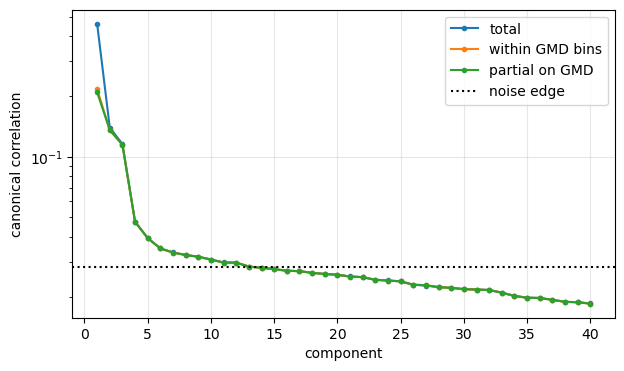

In [13]:
# ---- Canonical correlations ---------------------------------------------------------
def sqrt_and_inv_sqrt(S, rel_floor=1e-8):
    # symmetric square root and inverse square root of a covariance matrix
    lam, V = np.linalg.eigh(S)
    lam = np.clip(lam, rel_floor * lam.max(), None)
    return (V * np.sqrt(lam)) @ V.T, (V / np.sqrt(lam)) @ V.T


okD, okC = mD >= MIN_MEAN, mC >= MIN_MEAN
n_e, n_i = okD.sum(), okC.sum()
print(f"rank test on {n_e} electron x {n_i} ion TOF bins (mean >= {MIN_MEAN} counts/shot), N = {N:.0f}")
CCA = {}
for name, E in EST.items():
    Hd, Wd = sqrt_and_inv_sqrt(E["DD"][np.ix_(okD, okD)])
    Hc, Wc = sqrt_and_inv_sqrt(E["CC"][np.ix_(okC, okC)])
    U, s, Vt = np.linalg.svd(Wd @ E["DC"][np.ix_(okD, okC)] @ Wc, full_matrices=False)
    edge = (np.sqrt(n_e) + np.sqrt(n_i)) / np.sqrt(N)
    CCA[name] = {"s": s, "edge": edge, "a": Hd @ U, "b": Hc @ Vt.T}
    print(f"  {name:16s} s = {np.array2string(s[:6], precision=4)}  edge {edge:.4f}"
          f"  -> {np.sum(s > edge)} above")

fig, ax = plt.subplots(figsize=(7, 4))
for name, r in CCA.items():
    s40 = r["s"][:40]
    ax.semilogy(np.arange(1, len(s40) + 1), s40, "o-", ms=3, label=name)
ax.axhline(edge, color="k", ls=":", label="noise edge")
ax.set(xlabel="component", ylabel="canonical correlation")
ax.legend()
plt.show()

### 5b. Leading components
Electron and ion loadings of the first `N_COMPONENTS` components of `WINDOW_EST`. The sign of each component is
arbitrary; it is flipped so the electron loading sums to a positive number. Components below the noise edge are noise.

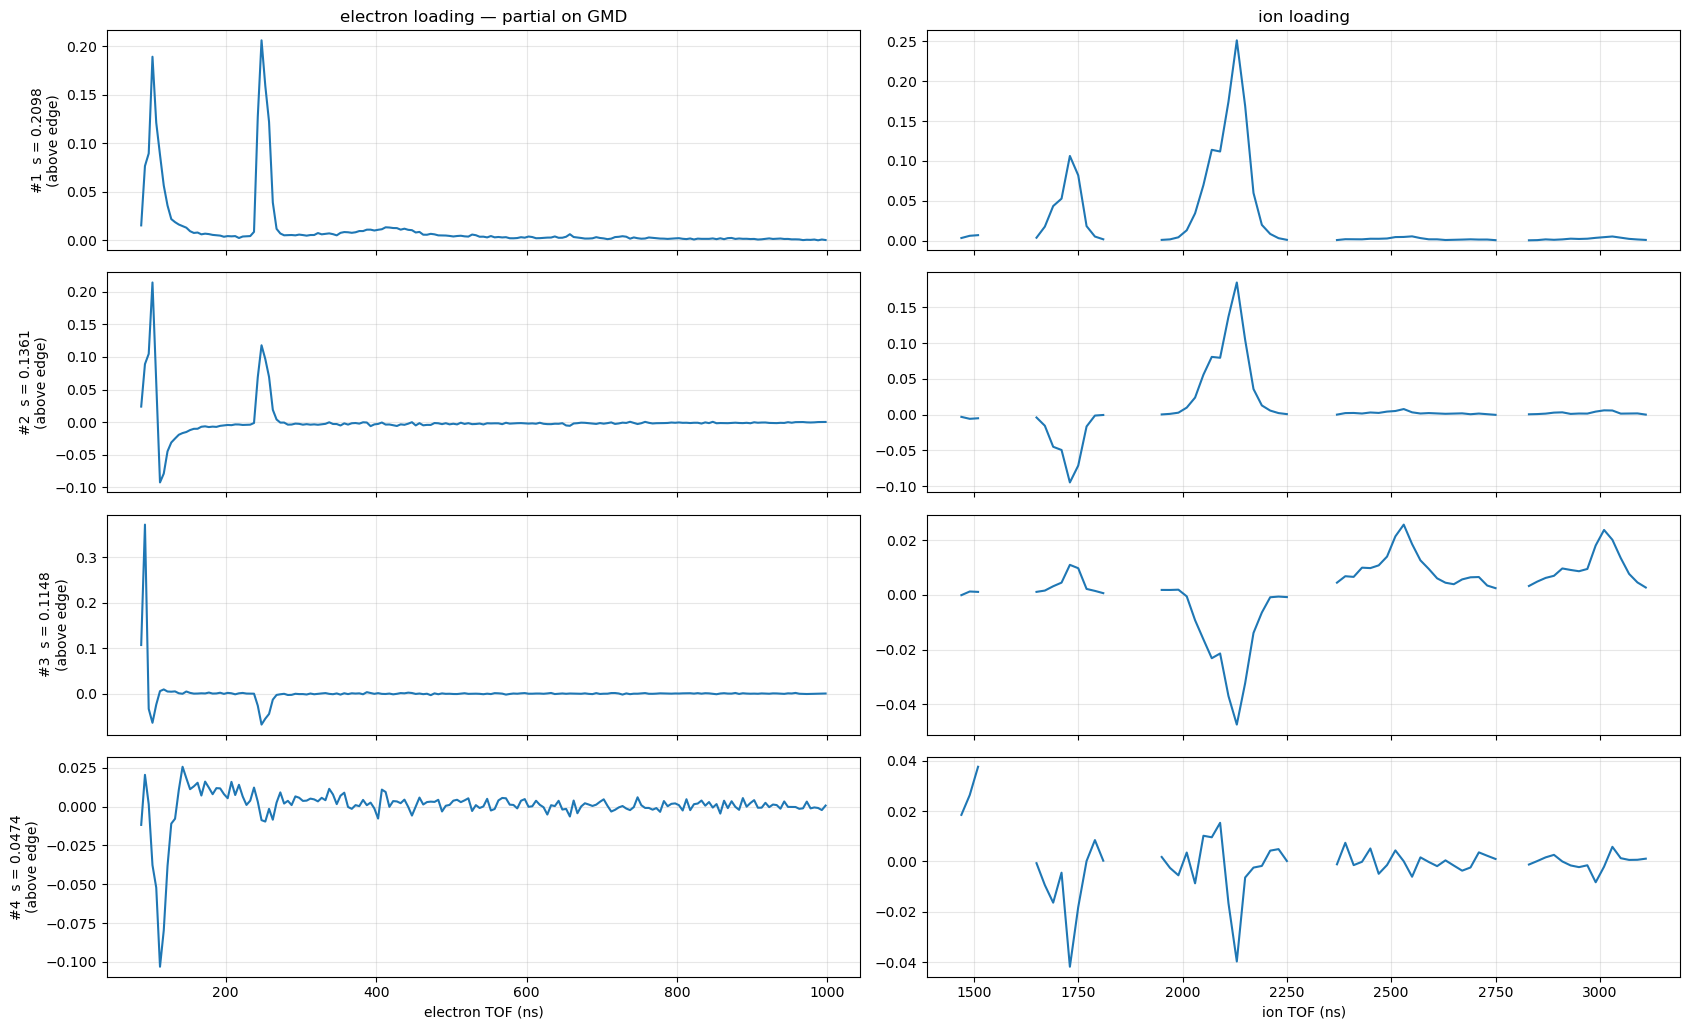

In [14]:
# ---- Loadings -----------------------------------------------------------------------
r = CCA[WINDOW_EST]
fig, ax = plt.subplots(N_COMPONENTS, 2, figsize=(17, 2.6 * N_COMPONENTS), sharex="col", squeeze=False)
for k in range(N_COMPONENTS):
    a = np.full(len(e_cent), np.nan)
    b = np.full(len(i_cent), np.nan)
    a[okD], b[okC] = r["a"][:, k], r["b"][:, k]
    sgn = np.sign(np.nansum(a)) or 1.0
    ax[k, 0].plot(e_cent, sgn * a)
    ax[k, 1].plot(i_cent, sgn * b)
    tag = "above" if r["s"][k] > r["edge"] else "below"
    ax[k, 0].set_ylabel(f"#{k + 1}  s = {r['s'][k]:.4f}\n({tag} edge)")
ax[0, 0].set_title(f"electron loading — {WINDOW_EST}")
ax[0, 1].set_title("ion loading")
ax[-1, 0].set_xlabel("electron TOF (ns)")
ax[-1, 1].set_xlabel("ion TOF (ns)")
fig.tight_layout()
plt.show()

## 6. What is left after the leading component
Top: the leading (rank-1) component $s_1 a_1 b_1^\mathsf{T}$; bottom: Cov(D, C) minus it. Both in standard errors.
A residual consistent with noise means the e–i covariance is one separable term; structure in the residual is the
non-trivial part (bins below `MIN_MEAN` are not modelled and keep their covariance).

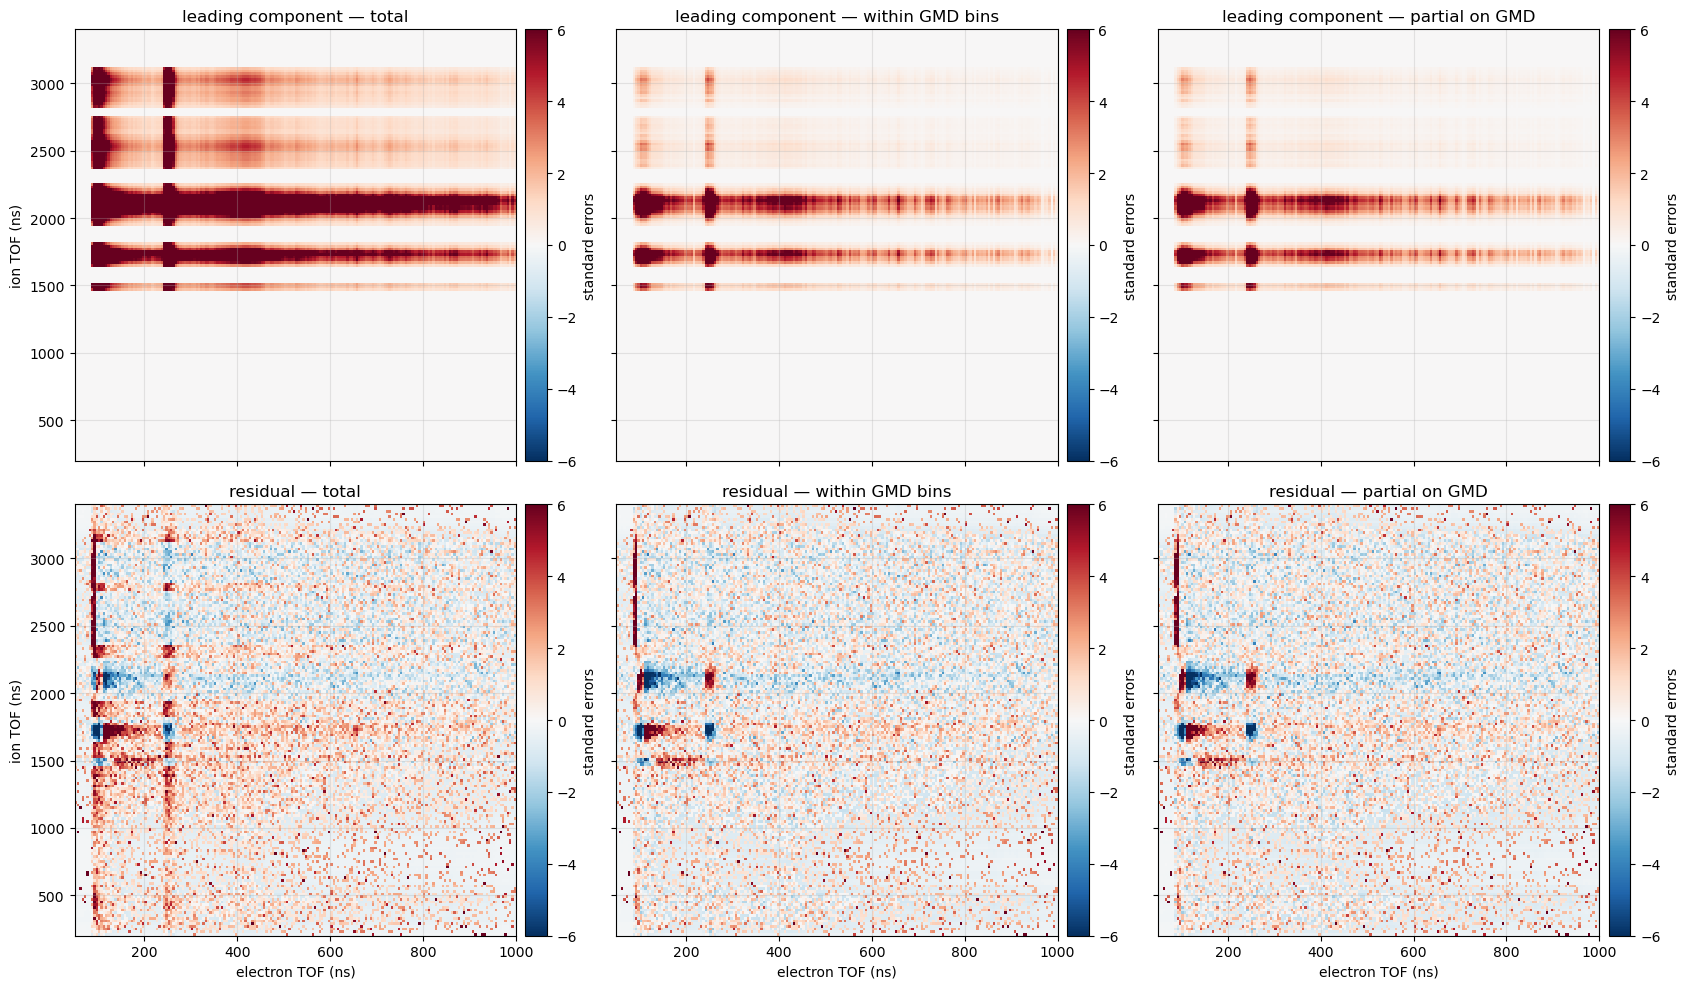

In [15]:
# ---- Rank-1 model and residual ------------------------------------------------------
fig, ax = plt.subplots(2, 3, figsize=(17, 10), sharex=True, sharey=True)
for k, (name, E) in enumerate(EST.items()):
    r = CCA[name]
    rank1 = np.zeros_like(E["DC"])
    rank1[np.ix_(okD, okC)] = r["s"][0] * np.outer(r["a"][:, 0], r["b"][:, 0])
    resid = E["DC"] - rank1
    show_map(ax[0, k], (rank1 / E["se_DC"]).T, e_edges, i_edges, vmax=Z_MAX, label="standard errors")
    show_map(ax[1, k], (resid / E["se_DC"]).T, e_edges, i_edges, vmax=Z_MAX, label="standard errors")
    ax[0, k].set_title(f"leading component — {name}")
    ax[1, k].set_title(f"residual — {name}")
    ax[1, k].set_xlabel("electron TOF (ns)")
for a in ax[:, 0]:
    a.set_ylabel("ion TOF (ns)")
fig.tight_layout()
plt.show()

## 7. Per GMD bin
Canonical correlations of the partial (on GMD) covariance inside each GMD bin, and the partial e–i covariance maps
in standard errors. Structure that is absent at low pulse energy and grows with it points to a nonlinear process.
With few counts per shot the noise edge is optimistic: the shifted-train control above put up to 4 null components
over it in the lowest GMD bin, 1–2 in the bins up to 0.15 µJ and none above that. Trust components well above the
edge.

  bin  0  <G> = 0.031 uJ  shots   44229  s = [0.2767 0.1638 0.1468 0.1319 0.1259]  edge 0.1021  -> 13 above
  bin  1  <G> = 0.050 uJ  shots   52930  s = [0.2696 0.1651 0.1374 0.1181 0.1098]  edge 0.0933  -> 11 above
  bin  2  <G> = 0.072 uJ  shots   58194  s = [0.2592 0.1669 0.1441 0.1114 0.1008]  edge 0.0890  -> 8 above
  bin  3  <G> = 0.100 uJ  shots   59882  s = [0.247  0.1652 0.1453 0.0943 0.0911]  edge 0.0877  -> 6 above
  bin  4  <G> = 0.132 uJ  shots   62482  s = [0.2439 0.156  0.1451 0.0934 0.0892]  edge 0.0859  -> 7 above
  bin  5  <G> = 0.169 uJ  shots   64157  s = [0.2321 0.1598 0.1326 0.0897 0.0839]  edge 0.0847  -> 4 above
  bin  6  <G> = 0.214 uJ  shots   61205  s = [0.2309 0.1535 0.1467 0.091  0.0869]  edge 0.0868  -> 5 above
  bin  7  <G> = 0.272 uJ  shots   59378  s = [0.2242 0.1511 0.1326 0.092  0.0873]  edge 0.0881  -> 4 above
  bin  8  <G> = 0.364 uJ  shots   58061  s = [0.2131 0.1528 0.126  0.0942 0.0917]  edge 0.0891  -> 5 above
  bin  9  <G> = 0.515 uJ  shots   4

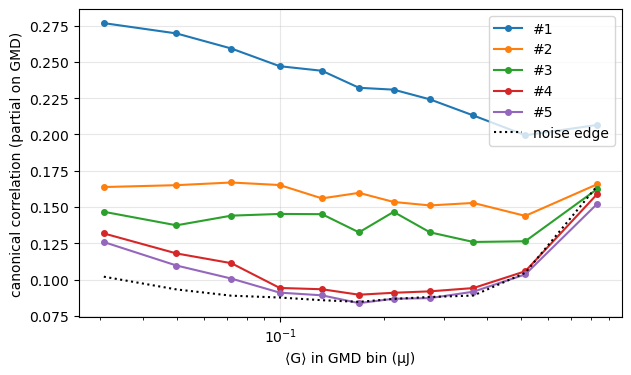

In [16]:
# ---- Canonical correlations per GMD bin ---------------------------------------------
n_show = 5
s_bin = np.full((len(bins), n_show), np.nan)
edge_bin = (np.sqrt(n_e) + np.sqrt(n_i)) / np.sqrt(n_b)
for j in range(len(bins)):
    _, Wd = sqrt_and_inv_sqrt(pDD[j][np.ix_(okD, okD)])
    _, Wc = sqrt_and_inv_sqrt(pCC[j][np.ix_(okC, okC)])
    s = np.linalg.svd(Wd @ pDC[j][np.ix_(okD, okC)] @ Wc, compute_uv=False)
    s_bin[j] = s[:n_show]
    print(f"  bin {bins[j]:2d}  <G> = {G[j]:.3f} uJ  shots {n_b[j]:7.0f}  s = {np.array2string(s_bin[j], precision=4)}"
          f"  edge {edge_bin[j]:.4f}  -> {np.sum(s > edge_bin[j])} above")

fig, ax = plt.subplots(figsize=(7, 4))
for k in range(n_show):
    ax.plot(G, s_bin[:, k], "o-", ms=4, label=f"#{k + 1}")
ax.plot(G, edge_bin, "k:", label="noise edge")
ax.set(xscale="log", xlabel="⟨G⟩ in GMD bin (µJ)", ylabel="canonical correlation (partial on GMD)")
ax.legend()
plt.show()

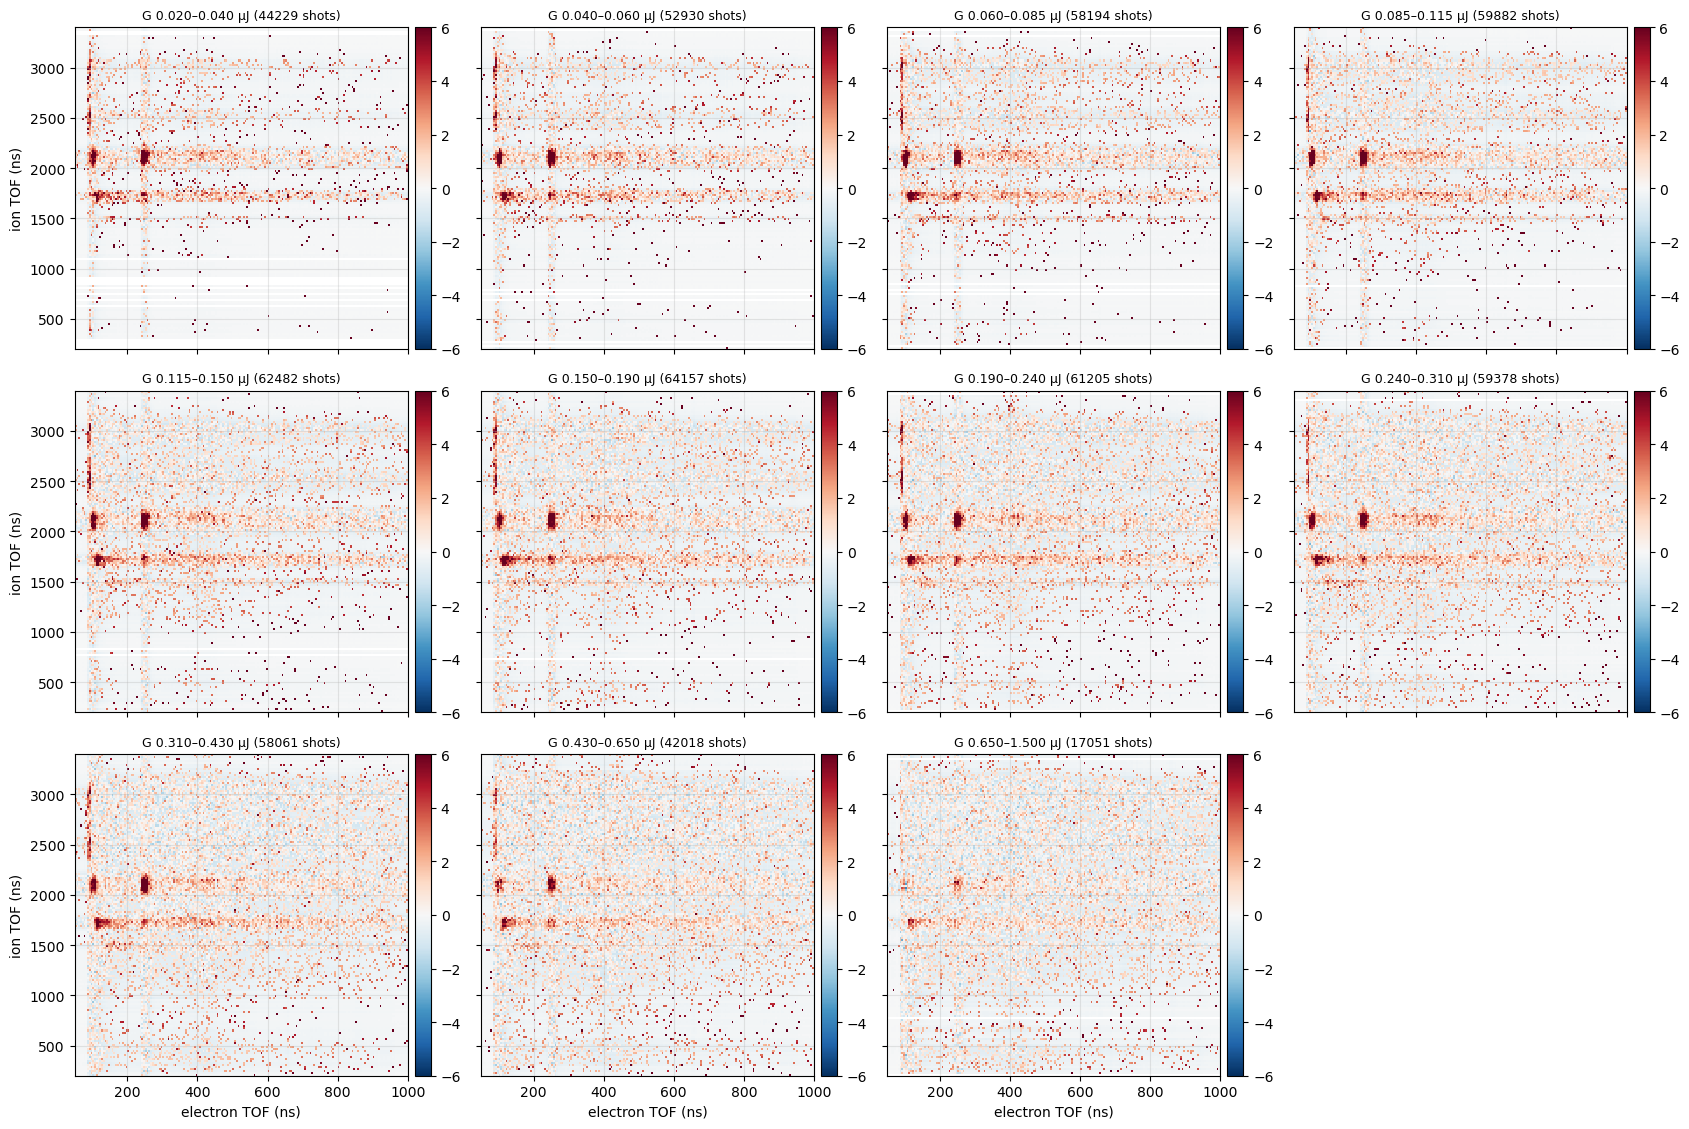

In [17]:
# ---- Partial e–i covariance per GMD bin (standard errors) ---------------------------
n_col = 4
n_row = int(np.ceil(len(bins) / n_col))
fig, ax = plt.subplots(n_row, n_col, figsize=(17, 3.8 * n_row), sharex=True, sharey=True, squeeze=False)
for j in range(len(bins)):
    se = np.sqrt(np.outer(np.clip(np.diag(pDD[j]), 0, None), np.clip(np.diag(pCC[j]), 0, None)) / n_b[j])
    se[se == 0] = np.nan
    show_map(ax.flat[j], (pDC[j] / se).T, e_edges, i_edges, vmax=Z_MAX)
    ax.flat[j].set_title(f"G {agg.gmd_edges[bins[j]]:.3f}–{agg.gmd_edges[bins[j] + 1]:.3f} µJ ({n_b[j]:.0f} shots)",
                         fontsize=9)
for a in ax.flat[len(bins):]:
    a.set_visible(False)
for a in ax[-1]:
    a.set_xlabel("electron TOF (ns)")
for a in ax[:, 0]:
    a.set_ylabel("ion TOF (ns)")
fig.tight_layout()
plt.show()